# NumCompute quickstart

An end-to-end tour of the toolkit on the **Titanic** passenger data in `demo/data/`. It uses only Python and NumPy.

| Step | Module(s) |
|---|---|
| 1. Read CSV files that contain missing values and quoted text | `io` |
| 2. Impute, scale and one-hot encode | `preprocessing` |
| 3. Top-k, quickselect, binary search, multi-key sort | `sort_search` |
| 4. Tie-aware ranks and percentiles | `rank` |
| 5. Descriptive and streaming statistics, histograms, quantiles | `stats` |
| 6. Finite-difference gradients and Jacobians | `optim` |
| 7. Chain everything in a pipeline, train a model, evaluate | `pipeline`, `metrics` |
| 8. Benchmark Python loops against the vectorised versions | `benchmarking` |

**Run it:** from the repository root, run `pip install -e ".[dev]"`, then open this notebook and choose *Run All*.

In [1]:
from pathlib import Path

import numpy as np
import svgplot  # our small SVG chart helper in demo/svgplot.py (NumPy only)

import numcompute as nc
from numcompute import io, metrics, optim, rank, sort_search, stats, utils
from numcompute import preprocessing as pp
from numcompute.pipeline import BaseEstimator, ColumnSelector, FeatureUnion, Pipeline

np.set_printoptions(precision=3, suppress=True)

# The notebook may be started from demo/ or from the repo root, so look for the data
if Path("data/train.csv").exists():
    DATA = Path("data")
else:
    DATA = Path("demo/data")
ROOT = DATA.resolve().parent.parent
FIGS = ROOT / "report" / "figures"  # the report uses the charts saved here

print("numcompute", nc.__version__, "| numpy", np.__version__, "| data:", DATA)

numcompute 0.1.0 | numpy 2.5.3 | data: data


## 1. Reading CSV files (`io`)

`train.csv` has 891 passengers. Some cells are empty (`Age`, `Cabin`, `Embarked`), and the `Name` field contains quoted commas such as `"Braund, Mr. Owen Harris"`. A plain `np.genfromtxt` would split those names at the comma and shift every column after them. `load_csv` handles the quotes, lets you choose columns by name, and gives a choice of three policies for missing values.

In [2]:
train = DATA / "train.csv"
print(io.read_header(train))

num_cols = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
cat_cols = ["Sex", "Embarked"]

X_num = io.load_csv(train, usecols=num_cols)  # numbers: empty cells become NaN
X_cat = io.load_csv(train, usecols=cat_cols, dtype=str)  # text: empty cells become ""
names = io.load_csv(train, usecols="Name", dtype=str)[:, 0]
y = io.load_csv(train, usecols="Survived", dtype=int)[:, 0]

print("numeric", X_num.shape, "| categorical", X_cat.shape, "| labels", y.shape)

n_missing = np.isnan(X_num).sum(axis=0).tolist()
print("missing per numeric column:", dict(zip(num_cols, n_missing, strict=True)))
print("empty Embarked cells:", int((X_cat[:, 1] == "").sum()))
print("quoted name kept whole:", names[0])

['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
numeric (891, 5) | categorical (891, 2) | labels (891,)
missing per numeric column: {'Pclass': 0, 'Age': 177, 'SibSp': 0, 'Parch': 0, 'Fare': 0}
empty Embarked cells: 2
quoted name kept whole: Braund, Mr. Owen Harris


In [3]:
# load_csv has three ways to deal with missing cells
skipped = io.load_csv(train, usecols=num_cols, missing="skip")
filled = io.load_csv(train, usecols=num_cols, fill_value=-1.0)
print("skip  ->", skipped.shape, "(rows with any missing value dropped)")
print("fill  ->", filled[5], "(row 6: Age filled with -1)")
try:
    io.load_csv(train, usecols=num_cols, missing="raise")
except ValueError as err:
    print("raise ->", err)

# A big file can be read in chunks, so only one chunk is in memory at a time
chunks = io.iter_csv_chunks(train, chunksize=250, usecols=num_cols)
print("chunk sizes:", [len(chunk) for chunk in chunks])

skip  -> (714, 5) (rows with any missing value dropped)
fill  -> [ 3.    -1.     0.     0.     8.458] (row 6: Age filled with -1)
raise -> missing value at data row 7, column 1 (missing='raise')
chunk sizes: [250, 250, 250, 141]


## 2. Preprocessing (`preprocessing`)

Every transformer follows the same `fit` → `transform` API. The scalers ignore NaN when fitting and pass it through unchanged, so imputation can happen either before or after scaling.

In [4]:
imputer = pp.SimpleImputer(strategy="median").fit(X_num)
medians = dict(zip(num_cols, imputer.statistics_.tolist(), strict=True))
print("median per column (used to fill NaN):", medians)
X_filled = imputer.transform(X_num)

scaler = pp.StandardScaler().fit(X_filled)
Z = scaler.transform(X_filled)
print("after StandardScaler  mean:", Z.mean(axis=0), " std:", Z.std(axis=0))
print("round trip exact:", np.allclose(scaler.inverse_transform(Z), X_filled))

minmax = pp.MinMaxScaler(feature_range=(0, 1)).fit(X_filled)
scaled = minmax.transform(X_filled)
print("MinMaxScaler range per column:", scaled.min(axis=0), "to", scaled.max(axis=0))

median per column (used to fill NaN): {'Pclass': 3.0, 'Age': 28.0, 'SibSp': 0.0, 'Parch': 0.0, 'Fare': 14.4542}
after StandardScaler  mean: [ 0.  0. -0. -0.  0.]  std: [1. 1. 1. 1. 1.]
round trip exact: True
MinMaxScaler range per column: [0. 0. 0. 0. 0.] to [1. 1. 1. 1. 1.]


In [5]:
# Embarked has two blank cells, so fill them with the most common port first
cat_imputer = pp.SimpleImputer(strategy="most_frequent", missing_values="")
X_cat_filled = cat_imputer.fit_transform(X_cat)
print("Embarked blanks filled with:", cat_imputer.statistics_[1])

encoder = pp.OneHotEncoder(handle_unknown="ignore").fit(X_cat_filled)
print(encoder.get_feature_names(cat_cols))
print(encoder.transform(X_cat_filled[:3]))

Embarked blanks filled with: S
['Sex=female', 'Sex=male', 'Embarked=C', 'Embarked=Q', 'Embarked=S']
[[0. 1. 0. 0. 1.]
 [1. 0. 1. 0. 0.]
 [1. 0. 0. 0. 1.]]


## 3. Sorting and searching (`sort_search`)

* `topk` runs in O(n + k log k) using `np.argpartition`. When values tie, the row with the lower index wins, so the result is deterministic.
* `quickselect` returns the k-th smallest value in expected O(n) time. It uses a three-way vectorised partition, so many equal fares cost nothing extra.
* `binary_search` searches for many query values at once and returns each insertion index plus whether the value was found.

In [6]:
fare = X_num[:, num_cols.index("Fare")]
top_fares, top_rows = sort_search.topk(fare, 5)
print("top-5 fares:", top_fares, "rows:", top_rows)
print("(three passengers tie at 512.33 and come back in row order)")
for row in top_rows[:3]:
    print("   ", names[row])

sorted_fare = np.sort(fare)
middle = len(fare) // 2
median_fare = sort_search.quickselect(fare, middle)
print("quickselect median fare:", median_fare, "| full sort gives", sorted_fare[middle])

queries = np.array([7.25, 100.0, 1000.0])
positions, found = sort_search.binary_search(sorted_fare, queries)
print("binary_search insertion index:", positions, "found:", found)

top-5 fares: [512.329 512.329 512.329 263.    263.   ] rows: [258 679 737  27  88]
(three passengers tie at 512.33 and come back in row order)
    Ward, Miss. Anna
    Cardeza, Mr. Thomas Drake Martinez
    Lesurer, Mr. Gustave J
quickselect median fare: 14.4542 | full sort gives 14.4542
binary_search insertion index: [ 70 838 891] found: [ True False False]


In [7]:
# Sort by class (low to high), then by age (oldest first); unknown ages count as -1
ages = np.nan_to_num(X_num[:, 1], nan=-1)
table = np.column_stack([X_num[:, 0], ages])
sorted_table = sort_search.multikey_sort(table, keys=[0, 1], descending=[False, True])
print(sorted_table[:5])

# A stable sort keeps equal values in their original order, even when descending
values, positions = sort_search.stable_sort(
    [3, 1, 3, 2], descending=True, return_indices=True
)
print("sorted:", values, "| original positions:", positions)

[[ 1. 80.]
 [ 1. 71.]
 [ 1. 71.]
 [ 1. 70.]
 [ 1. 65.]]
sorted: [3 3 2 1] | original positions: [0 2 3 1]


## 4. Ranking and percentiles (`rank`)

Pclass contains many ties, which makes it a good test of the tie-handling methods.

In [8]:
pclass = X_num[:6, 0]
print("Pclass:", pclass)
for method in ["average", "min", "max", "dense", "ordinal"]:
    print(f"{method:>8}:", rank.rank(pclass, method=method))

age = X_num[:, 1]
print("\nAge ranks keep NaN as NaN:", rank.rank(age[:8]))
for interp in ["linear", "lower", "higher", "midpoint", "nearest"]:
    q = rank.percentile(age, [25, 50, 75], interpolation=interp, nan_policy="omit")
    print(f"Age 25/50/75th percentile ({interp:>8}):", q)

share = float(rank.percentileofscore(age, 30))
print(f"A 30-year-old is older than {share:.1f} % of passengers")

Pclass: [3. 1. 3. 1. 3. 3.]
 average: [4.5 1.5 4.5 1.5 4.5 4.5]
     min: [3. 1. 3. 1. 3. 3.]
     max: [6. 2. 6. 2. 6. 6.]
   dense: [2. 1. 2. 1. 2. 2.]
 ordinal: [3. 1. 4. 2. 5. 6.]

Age ranks keep NaN as NaN: [2.  6.  3.  4.5 4.5 nan 7.  1. ]
Age 25/50/75th percentile (  linear): [20.125 28.    38.   ]
Age 25/50/75th percentile (   lower): [20. 28. 38.]
Age 25/50/75th percentile (  higher): [20.5 28.  38. ]
Age 25/50/75th percentile (midpoint): [20.25 28.   38.  ]
Age 25/50/75th percentile ( nearest): [20. 28. 38.]
A 30-year-old is older than 55.6 % of passengers


## 5. Statistics (`stats`)

The axis rules follow NumPy: `axis=0` gives one value per column. `nan_policy` chooses what to do with NaN: `"propagate"`, `"omit"` or `"raise"`.

In [9]:
print("mean (propagate):", stats.mean(X_num, axis=0))
print("mean (omit)     :", stats.mean(X_num, axis=0, nan_policy="omit"))
print("var  (ddof=1)   :", stats.var(X_num, axis=0, ddof=1, nan_policy="omit"))

# describe() gives a dict of per-column results; print it as a small table
summary = stats.describe(X_num, nan_policy="omit")
print()
print(" " * 9 + "".join(f"{col:>10}" for col in num_cols))
for key in ["count", "mean", "std", "min", "q25", "median", "q75", "max"]:
    row = np.atleast_1d(summary[key])
    print(f"{key:>9}" + "".join(f"{value:>10.2f}" for value in row))

mean (propagate): [ 2.309    nan  0.523  0.382 32.204]
mean (omit)     : [ 2.309 29.699  0.523  0.382 32.204]
var  (ddof=1)   : [   0.699  211.019    1.216    0.65  2469.437]

             Pclass       Age     SibSp     Parch      Fare
    count    891.00    714.00    891.00    891.00    891.00
     mean      2.31     29.70      0.52      0.38     32.20
      std      0.84     14.52      1.10      0.81     49.67
      min      1.00      0.42      0.00      0.00      0.00
      q25      2.00     20.12      0.00      0.00      7.91
   median      3.00     28.00      0.00      0.00     14.45
      q75      3.00     38.00      1.00      0.00     31.00
      max      3.00     80.00      8.00      6.00    512.33


In [10]:
counts, edges = stats.histogram(age, bins=8)  # NaN ages are left out
print("Age histogram:")
for lo, hi, count in zip(edges[:-1], edges[1:], counts, strict=True):
    bar = "#" * (count // 5)
    print(f"  [{lo:5.1f}, {hi:5.1f})  {count:4d}  {bar}")

print("Fare quantiles 10/50/90%:", stats.quantile(fare, [0.1, 0.5, 0.9]))

# Read the file again, 100 rows at a time, keeping running (Welford) statistics.
# They should match the one-pass numbers from describe() above.
running = stats.RunningStats()
for chunk in io.iter_csv_chunks(train, chunksize=100, usecols=num_cols):
    running.update(chunk)
same_mean = np.allclose(running.mean, summary["mean"])
same_std = np.allclose(running.std(), summary["std"])
print("streaming mean:", running.mean, "| matches batch:", same_mean)
print("streaming std :", running.std(), "| matches batch:", same_std)

Age histogram:
  [  0.4,  10.4)    64  ############
  [ 10.4,  20.3)   115  #######################
  [ 20.3,  30.3)   230  ##############################################
  [ 30.3,  40.2)   155  ###############################
  [ 40.2,  50.2)    86  #################
  [ 50.2,  60.1)    42  ########
  [ 60.1,  70.1)    17  ###
  [ 70.1,  80.0)     5  #
Fare quantiles 10/50/90%: [ 7.55  14.454 77.958]
streaming mean: [ 2.309 29.699  0.523  0.382 32.204] | matches batch: True
streaming std : [ 0.836 14.516  1.102  0.806 49.666] | matches batch: True


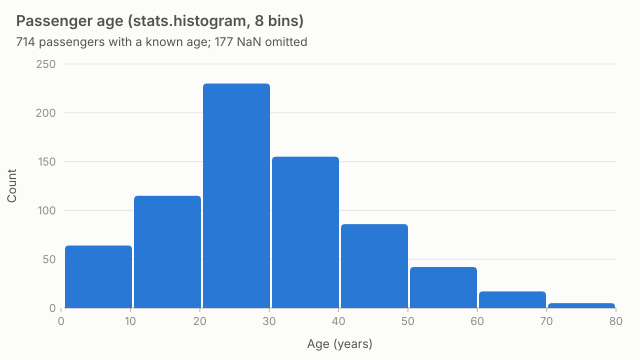

In [11]:
known = int(counts.sum())
unknown = int(np.isnan(age).sum())
fig = svgplot.histogram(
    counts,
    edges,
    title="Passenger age (stats.histogram, 8 bins)",
    subtitle=f"{known} passengers with a known age; {unknown} NaN omitted",
    xlabel="Age (years)",
)
fig.save(FIGS / "age_histogram.svg")
fig

## 6. Finite-difference gradients (`optim`)

First, compare against a known analytic gradient. The central difference has O(h²) error and the forward difference O(h). Round-off error grows as h shrinks, so each method has a best step size: about 1e-5 for central and 1e-8 for forward.

In [12]:
# Rosenbrock function: f(x, y) = (1 - x)^2 + 100 (y - x^2)^2
def f(v):
    x, y = v
    return (1 - x) ** 2 + 100 * (y - x * x) ** 2


def f_grad(v):  # the gradient worked out by hand
    x, y = v
    dx = -2 * (1 - x) - 400 * x * (y - x * x)
    dy = 200 * (y - x * x)
    return np.array([dx, dy])


start = np.array([-1.2, 1.0])
print("analytic  :", f_grad(start))
print("central   :", optim.grad(f, start))
print(f"check_grad relative error: {optim.check_grad(f, f_grad, start):.1e}")

# How does the error change with the step size h? We use an ordinary point here,
# because at the textbook start point the errors happen to cancel (see the report).
point = np.array([1.37, 2.11])


def max_error(h, method):
    estimate = optim.grad(f, point, h=h, method=method)
    return np.abs(estimate - f_grad(point)).max()


print(f"\n{'h':>8} {'central error':>15} {'forward error':>15}")
for h in [1e-1, 1e-3, 1e-5, 1e-7, 1e-9, 1e-11]:
    central_err, forward_err = max_error(h, "central"), max_error(h, "forward")
    print(f"{h:>8.0e} {central_err:>15.2e} {forward_err:>15.2e}")

analytic  : [-215.6  -88. ]
central   : [-215.6  -88. ]
check_grad relative error: 1.0e-10

       h   central error   forward error
   1e-01        5.48e+00        7.61e+01
   1e-03        5.48e-04        7.06e-01
   1e-05        5.45e-08        7.05e-03
   1e-07        1.56e-08        7.05e-05
   1e-09        7.11e-08        8.17e-07
   1e-11        8.79e-05        4.01e-04


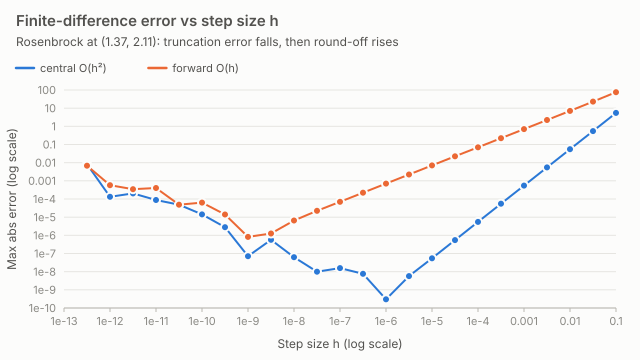

In [13]:
steps = 10.0 ** np.arange(-1, -13, -0.5)
central = [max_error(h, "central") for h in steps]
forward = [max_error(h, "forward") for h in steps]

fig = svgplot.line_chart(
    [("central O(h²)", steps, central), ("forward O(h)", steps, forward)],
    title="Finite-difference error vs step size h",
    subtitle="Rosenbrock at (1.37, 2.11): truncation error falls, then round-off rises",
    xlabel="Step size h (log scale)",
    ylabel="Max abs error (log scale)",
    logx=True,
    logy=True,
    markers=True,
    width=640,
)
fig.save(FIGS / "finite_difference_error.svg")
fig

In [14]:
def F(v):  # a function from R^2 to R^2
    return np.array([v[0] ** 2 * v[1], 5 * v[0] + np.sin(v[1])])


x1 = np.array([1.0, 2.0])
exact = np.array([[2 * x1[0] * x1[1], x1[0] ** 2], [5, np.cos(x1[1])]])
print("numerical Jacobian:\n", optim.jacobian(F, x1))
print("analytic Jacobian:\n", exact)

# Softmax outputs always add up to 1, so every column of its Jacobian sums to 0
J = optim.jacobian(utils.softmax, np.array([1.0, 2.0, 3.0]))
print("softmax Jacobian column sums:", J.sum(axis=0))

numerical Jacobian:
 [[ 4.     1.   ]
 [ 5.    -0.416]]
analytic Jacobian:
 [[ 4.     1.   ]
 [ 5.    -0.416]]
softmax Jacobian column sums: [ 0. -0. -0.]


## 7. Pipeline, model and metrics (`pipeline`, `metrics`)

The numeric columns are imputed then scaled, and the categorical columns are imputed then one-hot encoded. `FeatureUnion` joins the two branches side by side. The final step is a small logistic-regression estimator: it follows the `fit`/`predict` protocol and trains with the toolkit's own `sigmoid`, gradient check and Armijo line search.

In [15]:
class LogisticRegression(BaseEstimator):
    """A small logistic regression, trained by gradient descent with line search."""

    def __init__(self, n_iter=60):
        self.n_iter = n_iter

    @staticmethod
    def _add_bias(X):
        X = np.asarray(X, dtype=float)
        return np.hstack([X, np.ones((len(X), 1))])

    def fit(self, X, y):
        A = self._add_bias(X)
        y = np.asarray(y, dtype=float)

        def loss(w):
            # mean log-loss; logaddexp(0, z) is log(1 + e^z) without overflow
            z = A @ w
            return float(np.mean(np.logaddexp(0, z) - y * z))

        def gradient(w):
            return A.T @ (utils.sigmoid(A @ w) - y) / len(y)

        w = np.zeros(A.shape[1])
        # Check our hand-written gradient against finite differences first
        self.grad_check_ = optim.check_grad(loss, gradient, w + 0.1)
        for _ in range(self.n_iter):
            g = gradient(w)
            step = optim.backtracking_line_search(loss, w, -g, grad_x=g, alpha0=4.0)
            w = w - step * g
        self.coef_ = w
        self.loss_ = loss(w)
        return self

    def predict_proba(self, X):
        return utils.sigmoid(self._add_bias(X) @ self.coef_)

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)


# Put the 5 numeric and 2 text columns side by side in one object array
raw = np.hstack([X_num.astype(object), X_cat.astype(object)])

numeric = Pipeline([
    ("select", ColumnSelector([0, 1, 2, 3, 4], dtype=float)),
    ("impute", pp.SimpleImputer(strategy="median")),
    ("scale", pp.StandardScaler()),
])
categorical = Pipeline([
    ("select", ColumnSelector([5, 6])),
    ("impute", pp.SimpleImputer(strategy="most_frequent", missing_values="")),
    ("onehot", pp.OneHotEncoder(handle_unknown="ignore")),
])
model = Pipeline([
    ("features", FeatureUnion([("num", numeric), ("cat", categorical)])),
    ("clf", LogisticRegression()),
])
model.fit(raw, y)

clf = model["clf"]
feature_names = num_cols + categorical["onehot"].get_feature_names(cat_cols) + ["bias"]
weights = dict(zip(feature_names, np.round(clf.coef_, 2).tolist(), strict=True))
print(model)
print(f"\ngradient check: {clf.grad_check_:.1e} | final log-loss: {clf.loss_:.4f}")
print("weights:", weights)

Pipeline(steps=[('features', FeatureUnion(transformer_list=[('num', Pipeline(steps=[('select', ColumnSelector(columns=[0, 1, 2, 3, 4], dtype=<class 'float'>)), ('impute', SimpleImputer(strategy='median', fill_value=None, missing_values=nan)), ('scale', StandardScaler(with_mean=True, with_std=True))])), ('cat', Pipeline(steps=[('select', ColumnSelector(columns=[5, 6], dtype=None)), ('impute', SimpleImputer(strategy='most_frequent', fill_value=None, missing_values='')), ('onehot', OneHotEncoder(handle_unknown='ignore', drop=None, dtype=<class 'numpy.float64'>))]))])), ('clf', LogisticRegression(n_iter=60))])

gradient check: 1.5e-11 | final log-loss: 0.4408
weights: {'Pclass': -0.92, 'Age': -0.51, 'SibSp': -0.36, 'Parch': -0.07, 'Fare': 0.1, 'Sex=female': 1.34, 'Sex=male': -1.39, 'Embarked=C': 0.14, 'Embarked=Q': 0.08, 'Embarked=S': -0.27, 'bias': -0.06}


In [16]:
y_pred = model.predict(raw)
y_prob = clf.predict_proba(model["features"].transform(raw))
gender_rule = (X_cat[:, 0] == "female").astype(int)  # baseline: "women survive"

print(f"{'':>14} {'accuracy':>9} {'precision':>10} {'recall':>8} {'F1':>7}")
for label, pred in [("logistic", y_pred), ("gender rule", gender_rule)]:
    acc = metrics.accuracy(y, pred)
    p, r, f1 = metrics.precision_recall_f1(y, pred)
    print(f"{label:>14} {acc:>9.3f} {p:>10.3f} {r:>8.3f} {f1:>7.3f}")

cm = metrics.confusion_matrix(y, y_pred)
print("\nconfusion matrix (rows = true, cols = predicted):\n", cm)
print("row-normalised:\n", metrics.confusion_matrix(y, y_pred, normalize="true"))

macro_f1 = metrics.f1(y, y_pred, average="macro")
brier = metrics.mse(y, y_prob)  # mean squared error of the probabilities
print(f"macro F1: {macro_f1:.3f} | Brier score (MSE of probabilities): {brier:.4f}")

                accuracy  precision   recall      F1
      logistic     0.798      0.755    0.702   0.727
   gender rule     0.787      0.742    0.681   0.710

confusion matrix (rows = true, cols = predicted):
 [[471  78]
 [102 240]]
row-normalised:
 [[0.858 0.142]
 [0.298 0.702]]
macro F1: 0.783 | Brier score (MSE of probabilities): 0.1396


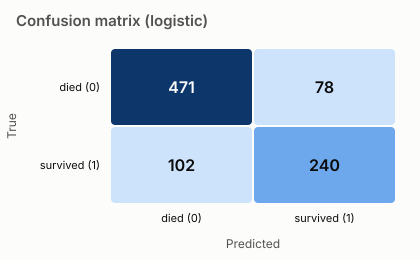

In [17]:
classes = ["died (0)", "survived (1)"]
fig = svgplot.heatmap(
    cm,
    classes,
    classes,
    title="Confusion matrix (logistic)",
    xlabel="Predicted",
    ylabel="True",
)
fig.save(FIGS / "confusion_matrix.svg")
fig

In [18]:
fpr, tpr, thresholds = metrics.roc_curve(y, y_prob)
auc_model = metrics.roc_auc_score(y, y_prob)
auc_rule = metrics.roc_auc_score(y, gender_rule)
print(f"ROC AUC: {auc_model:.4f} | gender rule AUC: {auc_rule:.4f}")

# Show 8 evenly spaced points along the curve
print(f"{'threshold':>10} {'FPR':>6} {'TPR':>6}")
for i in np.linspace(1, len(thresholds) - 1, 8).astype(int):
    print(f"{thresholds[i]:>10.3f} {fpr[i]:>6.3f} {tpr[i]:>6.3f}")

ROC AUC: 0.8571 | gender rule AUC: 0.7669
 threshold    FPR    TPR
     0.978  0.000  0.003
     0.844  0.007  0.313
     0.660  0.051  0.599
     0.442  0.179  0.737
     0.229  0.337  0.845
     0.124  0.554  0.909
     0.087  0.801  0.968
     0.007  1.000  1.000


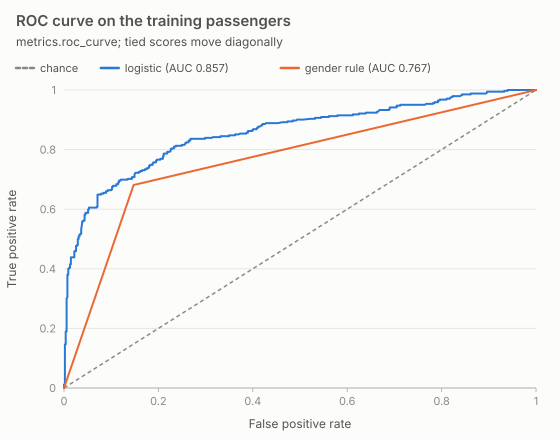

In [19]:
fpr_rule, tpr_rule, _ = metrics.roc_curve(y, gender_rule)
fig = svgplot.line_chart(
    [
        (f"logistic (AUC {auc_model:.3f})", fpr, tpr),
        (f"gender rule (AUC {auc_rule:.3f})", fpr_rule, tpr_rule),
    ],
    title="ROC curve on the training passengers",
    subtitle="metrics.roc_curve; tied scores move diagonally",
    xlabel="False positive rate",
    ylabel="True positive rate",
    xlim=(0, 1),
    ylim=(0, 1),
    reference=("chance", [0, 1], [0, 1]),
    width=560,
    height=440,
)
fig.save(FIGS / "roc_curve.svg")
fig

In [20]:
# Use the already-fitted pipeline on the unseen passengers in test.csv
test = DATA / "test.csv"
T_num = io.load_csv(test, usecols=num_cols)
T_cat = io.load_csv(test, usecols=cat_cols, dtype=str)
test_pred = model.predict(np.hstack([T_num.astype(object), T_cat.astype(object)]))

submission = DATA / "gender_submission.csv"
baseline = io.load_csv(submission, usecols="Survived", dtype=int)[:, 0]
agreement = metrics.accuracy(baseline, test_pred)

n_filled = int(np.isnan(T_num).sum())
print("test passengers:", len(test_pred),
      "| missing values filled by the pipeline:", n_filled)
print("predicted survival rate:", round(test_pred.mean(), 3))
print("agreement with gender_submission.csv:", round(agreement, 3))

test passengers: 418 | missing values filled by the pipeline: 87
predicted survival rate: 0.373
agreement with gender_submission.csv: 0.943


## 8. Benchmarks: Python loops vs vectorised NumPy (`benchmarking`)

`compare` first checks that both versions return the same values, then times them using warm-up runs, auto-ranging and repeated measurements. This is a short inline version; the full set of sizes is in `benchmark/run_benchmarks.py`, which writes its results to `benchmark/results/benchmarks.md`.

In [21]:
from numcompute.benchmarking import compare, environment_info, format_table

rng = np.random.default_rng(42)
x = rng.normal(size=50_000)
x_list = x.tolist()  # the loop versions work on plain Python lists
points = rng.normal(size=(150, 8))
points_list = points.tolist()


# Pure-Python versions to compare against
def loop_std(values):
    mean = sum(values) / len(values)
    return (sum((v - mean) ** 2 for v in values) / len(values)) ** 0.5


def loop_histogram(values, bins=20):
    lo, hi = min(values), max(values)
    counts = [0] * bins
    for v in values:
        i = int((v - lo) / (hi - lo) * bins)
        counts[min(i, bins - 1)] += 1  # the maximum goes in the last bin
    return counts


def loop_distances(rows):
    result = []
    for a in rows:
        row = []
        for b in rows:
            row.append(sum((p - q) ** 2 for p, q in zip(a, b, strict=True)) ** 0.5)
        result.append(row)
    return result


# compare() first checks that both versions give the same answer, then times them
results = []
results += compare(
    {"std: loop": lambda: loop_std(x_list), "std: numcompute": lambda: stats.std(x)},
    size=x.size,
    repeat=3,
)
results += compare(
    {
        "histogram: loop": lambda: loop_histogram(x_list),
        "histogram: numcompute": lambda: stats.histogram(x, 20)[0],
    },
    size=x.size,
    repeat=3,
)
results += compare(
    {
        "distances: loop": lambda: loop_distances(points_list),
        "distances: numcompute": lambda: utils.euclidean_distances(points),
    },
    size=len(points),
    repeat=3,
)
results += compare(
    {
        "top-10: full sort": lambda: np.sort(x)[::-1][:10],
        "top-10: numcompute": lambda: sort_search.topk(x, 10, return_indices=False),
    },
    size=x.size,
    repeat=3,
)
print(format_table(results))

env = environment_info()
print(f"\nPython {env['python']}, NumPy {env['numpy']}, {env['platform']}, "
      f"BLAS: {env['blas']}")

| Implementation | n | Best | Median | Speed-up |
|---|---:|---:|---:|---:|
| std: loop | 50,000 | 2.24 ms | 2.29 ms | 1.0× |
| std: numcompute | 50,000 | 34.9 µs | 35.4 µs | 64.3× |
| histogram: loop | 50,000 | 3.1 ms | 3.12 ms | 1.0× |
| histogram: numcompute | 50,000 | 313 µs | 326 µs | 9.9× |
| distances: loop | 150 | 13.6 ms | 13.7 ms | 1.0× |
| distances: numcompute | 150 | 59.4 µs | 59.8 µs | 229.1× |
| top-10: full sort | 50,000 | 986 µs | 993 µs | 1.0× |
| top-10: numcompute | 50,000 | 150 µs | 150 µs | 6.6× |

Python 3.14.6, NumPy 2.5.3, macOS-27.0-arm64-arm-64bit-Mach-O, BLAS: accelerate


The full benchmark (`python benchmark/run_benchmarks.py`) writes `benchmark/results/benchmarks.csv`. The cells below read that file with our own `io.load_csv`; the run name contains a comma, so this also tests quoted fields.

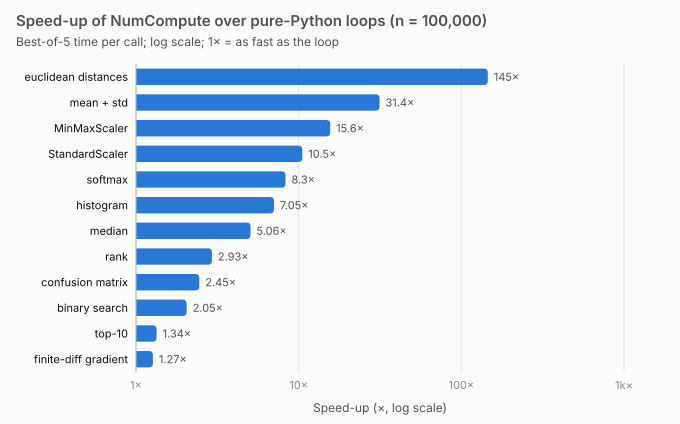

In [22]:
csv_path = ROOT / "benchmark" / "results" / "benchmarks.csv"
if not csv_path.exists():
    raise FileNotFoundError("run `python benchmark/run_benchmarks.py` first")

run_names = io.load_csv(csv_path, usecols="name", dtype=str)[:, 0]
speedups = io.load_csv(csv_path, usecols="speedup")[:, 0]

# A name looks like "rank (average, ties): numcompute"; the operation is "rank"
operation = np.array([name.split(": ")[0].split(" (")[0] for name in run_names])
# Rows come in pairs: the Python loop first, then our version
is_ours = np.arange(len(run_names)) % 2 == 1

# The file has 24 rows per problem size (12 cases, loop + numcompute) and the
# largest size (n = 100,000) comes last
in_last_block = np.arange(len(run_names)) >= len(run_names) - 24
pick = is_ours & in_last_block
order = np.argsort(-speedups[pick], kind="stable")

fig = svgplot.hbar_chart(
    operation[pick][order].tolist(),
    speedups[pick][order],
    title="Speed-up of NumCompute over pure-Python loops (n = 100,000)",
    subtitle="Best-of-5 time per call; log scale; 1× = as fast as the loop",
    xlabel="Speed-up (×, log scale)",
    logx=True,
    baseline=1,
    value_fmt="{:.3g}×",
    width=680,
)
fig.save(FIGS / "benchmark_speedup.svg")
fig

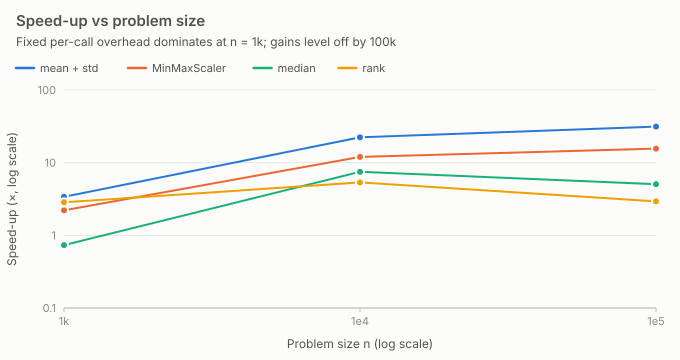

In [23]:
n_values = np.array([1_000, 10_000, 100_000])
series = []
for name in ["mean + std", "MinMaxScaler", "median", "rank"]:
    rows = is_ours & (operation == name)  # one row per problem size
    series.append((name, n_values, speedups[rows]))

fig = svgplot.line_chart(
    series,
    title="Speed-up vs problem size",
    subtitle="Fixed per-call overhead dominates at n = 1k; gains level off by 100k",
    xlabel="Problem size n (log scale)",
    ylabel="Speed-up (×, log scale)",
    logx=True,
    logy=True,
    markers=True,
    width=680,
)
fig.save(FIGS / "benchmark_scaling.svg")
fig

## Summary

* **io** loads CSV files that contain missing values and quoted commas, with a choice of fill, skip or raise for missing cells, and can also stream a file in chunks.
* **preprocessing + pipeline** turn mixed numeric and text columns into a clean 891×10 feature matrix with one `fit_transform` call. The fitted pipeline is then reused on `test.csv`.
* **sort_search / rank** give deterministic results when values tie, and their percentiles match NumPy for every interpolation mode.
* **stats**: the streaming (Welford) results equal the single-pass results exactly.
* **optim**: the finite-difference gradients agree with the analytic ones to about 1e-10.
* **metrics**: the pipeline model beats the "women survive" baseline on accuracy, F1 and AUC.
* **benchmarking**: vectorised code is tens to hundreds of times faster than the Python loops (see the table above).